# Neural Code Summarization: PLBART vs. CodeT5 on CodeXGLUE

**Task.** Given the body of a Python function, generate a one-sentence natural-language summary
(the first line of its docstring).

**Approach.** Two pre-trained code-aware encoder-decoder transformers, **PLBART** and **CodeT5**,
are fine-tuned on the Python subset of the **CodeXGLUE code-to-text** benchmark with a shared,
leakage-free training and evaluation pipeline, and compared with BLEU and ROUGE.

**Highlights**
- Honest model selection: the checkpoint with the best validation BLEU is kept, with early
  stopping, and the test set is scored exactly once per model.
- Fully reproducible: fixed seeds, pinned preprocessing, dynamic padding, every hyper-parameter in
  one place.
- Ready-to-use inference helper that applies the same preprocessing to arbitrary Python source.

### Contents
1. [Environment and configuration](#1.-Environment-and-configuration)
2. [Data](#2.-Data)
3. [Shared pipeline](#3.-Shared-pipeline)
4. [PLBART](#4.-PLBART)
5. [CodeT5](#5.-CodeT5)
6. [Results](#6.-Results)
7. [Inference on new code](#7.-Inference-on-new-code)
8. [Methodology notes](#8.-Methodology-notes)
9. [Conclusion and next steps](#9.-Conclusion-and-next-steps)


## 1. Environment and configuration

**Running on Kaggle (recommended).** This notebook was designed for a Kaggle GPU session:

- *Settings → Accelerator*: **GPU T4 x2** or **GPU P100**. Only one GPU is used.
- *Settings → Internet*: **On** (the dataset and model weights are downloaded from the Hugging Face Hub).
- Expected runtime on a T4 with the default 10% data subset: roughly 1.5-2.5 hours end to end
  (about 20 minutes with `SUBSET_FRACTION = 0.01`).
- Tested with Kaggle's current image (Python 3.13, PyTorch 2.11, transformers 5.20, datasets 4.8); the
  code also runs on transformers 4.4x.
- Outputs appear in the notebook's *Output* tab. `/kaggle/working/results` holds the metrics, test
  predictions and figures; copy that folder into the repository's `results/` directory.
  `/kaggle/working/checkpoints` holds the fine-tuned weights (about 1.4 GB, not meant for git).

Everything specific to Kaggle is marked with a `# Kaggle:` comment in the code.

In [1]:
# Kaggle: torch, transformers, datasets and nltk are pre-installed and already compatible with each
# other, so they are deliberately not upgraded here. Only the two missing packages are installed.
# The install needs "Internet: On" in the notebook settings.
%pip install -q rouge-score sentencepiece


Note: you may need to restart the kernel to use updated packages.


In [2]:
import ast
import io
import math
import re
import sys
import tokenize as py_tokenize
from pathlib import Path
from collections import Counter
from statistics import mean
from xml.sax.saxutils import unescape

import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    PLBartForConditionalGeneration,
    PLBartTokenizer,
    get_linear_schedule_with_warmup,
    set_seed,
)
from nltk.translate.bleu_score import corpus_bleu
from rouge_score import rouge_scorer

# ---- configuration -------------------------------------------------------------------------
SEED = 42
SUBSET_FRACTION = 0.1    # fraction of each split used. 0.1 -> ~25k training functions.
                         # Kaggle: ~1.5-2.5 h end to end on a T4 at 0.1; set 0.01 for a ~20 min smoke run.
                         # Runtime scales roughly linearly with this value.
MAX_SOURCE_LEN = 384     # tokens of code fed to the encoder
MAX_TARGET_LEN = 128     # tokens of summary produced by the decoder
NUM_EPOCHS = 10          # upper bound; early stopping normally ends training well before this
PATIENCE = 2             # epochs without validation-BLEU improvement before stopping
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.06
NUM_BEAMS = 4

# Kaggle: /kaggle/working is the only writable directory that is kept as notebook output.
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
CHECKPOINT_DIR = WORK_DIR / "checkpoints"   # fine-tuned weights (large, not committed to git)
RESULTS_DIR = WORK_DIR / "results"          # metrics, predictions and figures (copied into the repo)
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (CHECKPOINT_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import transformers, datasets
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU detected")
print("checkpoints ->", CHECKPOINT_DIR.resolve(), "| results ->", RESULTS_DIR.resolve())


torch 2.11.0+cu130 | transformers 5.20.2 | datasets 4.8.5
device: cuda | Tesla T4
checkpoints -> /kaggle/working/checkpoints | results -> /kaggle/working/results


## 2. Data

The [CodeXGLUE code-to-text](https://huggingface.co/datasets/google/code_x_glue_ct_code_to_text)
benchmark is derived from CodeSearchNet. Each Python example carries:

| field | content |
|---|---|
| `code` | the raw function source, **including** its docstring |
| `code_tokens` | the function tokenized with the docstring and comments **removed** |
| `docstring` | the full docstring |
| `docstring_tokens` | the tokenized first paragraph of the docstring (the summary) |

Following the benchmark's official recipe, the model input is `" ".join(code_tokens)` and the
target is `" ".join(docstring_tokens)`. Using `code` as the input would hand the model the answer
(see the leakage check in 2.3).

### 2.1 Load

In [3]:
dataset = load_dataset("google/code_x_glue_ct_code_to_text", "python")
dataset


README.md:   0%|          | 0.00/26.7k [00:00<?, ?B/s]

python/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

python/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

python/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  147MB            

python/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

python/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.7MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/251820 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13914 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/14918 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'repo', 'path', 'func_name', 'original_string', 'language', 'code', 'code_tokens', 'docstring', 'docstring_tokens', 'sha', 'url'],
        num_rows: 251820
    })
    validation: Dataset({
        features: ['id', 'repo', 'path', 'func_name', 'original_string', 'language', 'code', 'code_tokens', 'docstring', 'docstring_tokens', 'sha', 'url'],
        num_rows: 13914
    })
    test: Dataset({
        features: ['id', 'repo', 'path', 'func_name', 'original_string', 'language', 'code', 'code_tokens', 'docstring', 'docstring_tokens', 'sha', 'url'],
        num_rows: 14918
    })
})

### 2.2 Subsample and build text fields

The full training split has ~250k functions, far more than a short GPU session needs for a
comparison study. Each split is **shuffled with a fixed seed before subsampling**: the dataset is
ordered by repository, so taking the first N rows would yield a handful of projects rather than a
representative sample. Examples with an empty code or docstring side are dropped.

In [4]:
def take_subset(split, fraction, seed=SEED):
    n = max(1, int(len(split) * fraction))
    return split.shuffle(seed=seed).select(range(n))


def add_text_fields(example):
    return {
        "source": " ".join(example["code_tokens"]),
        "target": " ".join(example["docstring_tokens"]),
    }


def has_source_and_target(example):
    return len(example["code_tokens"]) > 0 and len(example["docstring_tokens"]) > 0


text = {}
for name in ("train", "validation", "test"):
    subset = take_subset(dataset[name], SUBSET_FRACTION).filter(has_source_and_target)
    text[name] = subset.map(add_text_fields)
    print(f"{name:>10}: {len(text[name]):>6} examples")

example = text["train"][0]
print("\nsource:", example["source"][:300], "...")
print("target:", example["target"])


Filter:   0%|          | 0/25182 [00:00<?, ? examples/s]

Map:   0%|          | 0/25182 [00:00<?, ? examples/s]

     train:  25182 examples


Filter:   0%|          | 0/1391 [00:00<?, ? examples/s]

Map:   0%|          | 0/1391 [00:00<?, ? examples/s]

validation:   1391 examples


Filter:   0%|          | 0/1491 [00:00<?, ? examples/s]

Map:   0%|          | 0/1491 [00:00<?, ? examples/s]

      test:   1491 examples

source: def metapolicy ( request , permitted , domains = None ) : if domains is None : domains = [ ] policy = policies . Policy ( * domains ) policy . metapolicy ( permitted ) return serve ( request , policy ) ...
target: Serves a cross - domain policy which can allow other policies to exist on the same domain .


### 2.3 Leakage check

A summarizer that can read the docstring inside its input is not summarizing, it is copying.
The check below measures how often the target summary occurs verbatim (ignoring case, whitespace
and punctuation) inside the model input, for the raw `code` field and for the `code_tokens`-based
source actually used here.

In [5]:
def canonical(s):
    # compare on alphanumerics only, so tokenization differences ("DeepMind - style" vs "DeepMind-style")
    # cannot hide a verbatim copy
    return "".join(ch for ch in s.lower() if ch.isalnum())


def leak_rate(split, source_field):
    hits = 0
    for ex in split:
        hits += canonical(ex["target"]) in canonical(ex[source_field])
    return hits / len(split)


rows = []
for name in ("train", "validation", "test"):
    rows.append({"split": name,
                 "target inside raw `code`": f"{leak_rate(text[name], 'code'):.1%}",
                 "target inside `code_tokens` source": f"{leak_rate(text[name], 'source'):.1%}"})
display(pd.DataFrame(rows).set_index("split"))

assert leak_rate(text["test"], "source") < 0.05, "target text is leaking into the model input"


,target inside raw `code`,target inside `code_tokens` source
split,,
train,100.0%,0.6%
validation,100.0%,0.9%
test,100.0%,0.7%


### 2.4 Length statistics

Used to confirm that `MAX_SOURCE_LEN` / `MAX_TARGET_LEN` truncate only a small tail of examples.

,count,mean,std,min,50%,90%,95%,99%,max
source words,25182.0,109.3,97.3,20.0,74.0,236.0,317.9,481.2,1018.0
target words,25182.0,11.4,8.4,3.0,9.0,20.0,27.0,45.2,222.0


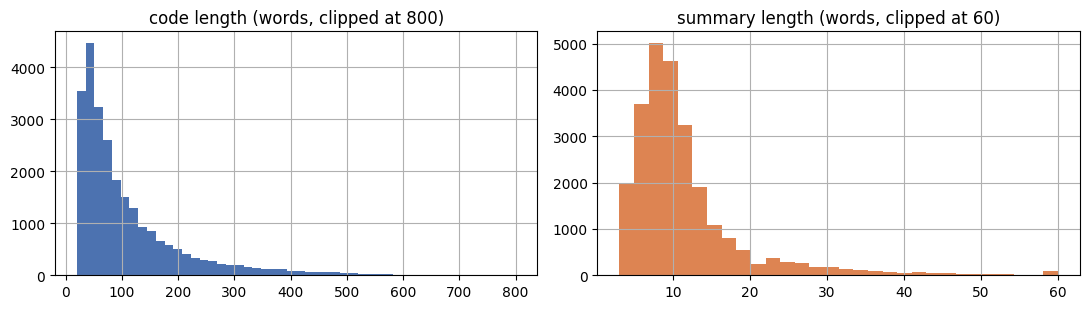

In [6]:
lengths = pd.DataFrame({
    "source words": [len(s.split()) for s in text["train"]["source"]],
    "target words": [len(t.split()) for t in text["train"]["target"]],
})
display(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
lengths["source words"].clip(upper=800).hist(bins=50, ax=axes[0], color="#4C72B0")
axes[0].set_title("code length (words, clipped at 800)")
lengths["target words"].clip(upper=60).hist(bins=30, ax=axes[1], color="#DD8452")
axes[1].set_title("summary length (words, clipped at 60)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "length_distribution.png", dpi=150, bbox_inches="tight")


## 3. Shared pipeline

Both models go through exactly the same code, so the comparison is fair.

- **Tokenization.** Targets are tokenized with `text_target=` so each tokenizer adds its own
  target-side special tokens (for PLBART this appends the `__en_XX__` language code, which is also
  what the decoder is started with at inference time).
- **Batching.** `DataCollatorForSeq2Seq` pads dynamically per batch and pads `labels` with `-100`,
  which the cross-entropy loss ignores.
- **Training.** AdamW with weight decay, linear warm-up/decay schedule, gradient clipping; after
  every epoch the validation set is decoded, and the checkpoint with the best validation BLEU is
  kept (early stopping once it stops improving).
- **Evaluation.** Beam-search generation; BLEU and ROUGE computed against the untruncated reference
  strings from the dataset.

### 3.1 Tokenization and data loaders

In [7]:
def tokenize_split(split, tokenizer):
    def tokenize(batch):
        model_inputs = tokenizer(batch["source"], max_length=MAX_SOURCE_LEN, truncation=True)
        labels = tokenizer(text_target=batch["target"], max_length=MAX_TARGET_LEN, truncation=True)
        model_inputs["labels"] = labels["input_ids"]
        return model_inputs

    return split.map(tokenize, batched=True, remove_columns=split.column_names)


def build_loaders(tokenizer, batch_size):
    collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)
    tokenized = {name: tokenize_split(split, tokenizer) for name, split in text.items()}
    generator = torch.Generator().manual_seed(SEED)
    return {
        "train": DataLoader(tokenized["train"], batch_size=batch_size, shuffle=True,
                            collate_fn=collator, generator=generator),
        "validation": DataLoader(tokenized["validation"], batch_size=batch_size, shuffle=False,
                                 collate_fn=collator),
        "test": DataLoader(tokenized["test"], batch_size=batch_size, shuffle=False,
                           collate_fn=collator),
    }


### 3.2 Generation and metrics

- **BLEU-4 (CodeXGLUE)**: the official CodeXGLUE code-to-text metric, smoothed sentence-level BLEU-4
  averaged over examples. It is re-implemented from the benchmark's evaluator so scores are directly
  comparable with the leaderboard. Text is lower-cased and punctuation is split off before matching,
  so `stream.` and `stream .` are the same tokens.
- **BLEU-4 (corpus)**: standard corpus-level BLEU-4 on the same tokens, without smoothing.
- **ROUGE-1/2/L**: mean F-measure over examples, with stemming.

All scores are on a 0-100 scale and deterministic. Every call creates its own scorer, so metrics
from different evaluations can never mix.

In [8]:
@torch.no_grad()
def generate_summaries(model, tokenizer, loader, **generate_kwargs):
    model.to(device).eval()
    outputs = []
    for batch in tqdm(loader, desc="generating", leave=False):
        generated = model.generate(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            max_new_tokens=MAX_TARGET_LEN,
            num_beams=NUM_BEAMS,
            early_stopping=True,
            **generate_kwargs,
        )
        outputs.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return [o.strip() for o in outputs]


# ---- BLEU: the CodeXGLUE code-to-text evaluator (smoothed sentence-level BLEU-4) ----------------
# Lower-casing and splitting off punctuation before n-gram matching matters here: PLBART's tokenizer
# re-attaches punctuation when decoding ("stream."), while the references are space-tokenized
# ("stream ."). A plain whitespace split would penalize that difference in spacing, not in content.
_BLEU_NORMALIZE1 = [(re.compile(p), r) for p, r in [("<skipped>", ""), (r"-\n", ""), (r"\n", " ")]]
_BLEU_NORMALIZE2 = [(re.compile(p), r) for p, r in [
    (r"([\{-\~\[-\` -\&\(-\+\:-\@\/])", r" \1 "),
    (r"([^0-9])([\.,])", r"\1 \2 "),
    (r"([\.,])([^0-9])", r" \1 \2"),
    (r"([0-9])(-)", r"\1 \2 "),
]]


def bleu_tokenize(text):
    s = " ".join(re.findall(r"[\w]+|[^\s\w]", text.strip().lower()))
    for pattern, repl in _BLEU_NORMALIZE1:
        s = pattern.sub(repl, s)
    s = f" {unescape(s, {'&quot;': chr(34)})} "
    for pattern, repl in _BLEU_NORMALIZE2:
        s = pattern.sub(repl, s)
    return s.split()


def _ngram_counts(words, n=4):
    counts = Counter()
    for k in range(1, n + 1):
        for i in range(len(words) - k + 1):
            counts[tuple(words[i:i + k])] += 1
    return counts


def smoothed_sentence_bleu(reference, hypothesis, n=4):
    ref, hyp = bleu_tokenize(reference), bleu_tokenize(hypothesis)
    ref_counts = _ngram_counts(ref, n)
    guess = [max(len(hyp) - k + 1, 0) for k in range(1, n + 1)]
    correct = [0] * n
    for gram, count in _ngram_counts(hyp, n).items():
        correct[len(gram) - 1] += min(ref_counts[gram], count)
    tiny = sys.float_info.min
    # add-one smoothing on 2- to 4-gram precisions, as in the CodeXGLUE evaluator
    log_bleu = sum(math.log(correct[k] + (k > 0) + tiny) - math.log(guess[k] + (k > 0) + tiny)
                   for k in range(n)) / n
    log_bleu += min(0.0, 1 - (len(ref) + 1) / (len(hyp) + 1))   # brevity penalty
    return math.exp(log_bleu)


def compute_bleu(predictions, references):
    sentence = mean(smoothed_sentence_bleu(r, p) for r, p in zip(references, predictions))
    corpus = corpus_bleu([[bleu_tokenize(r)] for r in references], [bleu_tokenize(p) for p in predictions])
    return {"BLEU-4 (CodeXGLUE)": 100 * sentence, "BLEU-4 (corpus)": 100 * corpus}


def compute_rouge(predictions, references):
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    scores = [scorer.score(ref, pred) for pred, ref in zip(predictions, references)]
    return {name: 100 * mean(score[key].fmeasure for score in scores)
            for name, key in (("ROUGE-1", "rouge1"), ("ROUGE-2", "rouge2"), ("ROUGE-L", "rougeL"))}


def evaluate_generation(model, tokenizer, loader, references, label, n_examples=5, **generate_kwargs):
    predictions = generate_summaries(model, tokenizer, loader, **generate_kwargs)
    assert len(predictions) == len(references), (len(predictions), len(references))
    metrics = {**compute_bleu(predictions, references), **compute_rouge(predictions, references)}

    print(f"\n{label}")
    for name, value in metrics.items():
        print(f"  {name:<22}{value:6.2f}")
    print()
    for pred, ref in list(zip(predictions, references))[:n_examples]:
        print(f"  generated: {pred}")
        print(f"  reference: {ref}\n")
    return metrics, predictions


### 3.3 Training loop

Model selection follows the CodeXGLUE recipe: after every epoch the model decodes the validation
set and the checkpoint with the best validation BLEU is kept. Validation loss is still logged, but
it is a poor proxy for generation quality (it can rise while BLEU still improves), so it is not
used for selection or early stopping.

In [9]:
def to_device(batch):
    return {k: v.to(device) for k, v in batch.items()}


@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    total, n = 0.0, 0
    for batch in loader:
        total += model(**to_device(batch)).loss.item()
        n += 1
    return total / max(n, 1)


def train_model(model, tokenizer, loaders, run_name, val_references, generate_kwargs=None,
                num_epochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    generate_kwargs = generate_kwargs or {}
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    total_steps = len(loaders["train"]) * num_epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRACTION * total_steps), total_steps)

    best_bleu, best_state, bad_epochs, history = -math.inf, None, 0, []
    for epoch in range(1, num_epochs + 1):
        model.train()
        running = []
        progress = tqdm(loaders["train"], desc=f"{run_name} epoch {epoch}/{num_epochs}", leave=False)
        for batch in progress:
            loss = model(**to_device(batch)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            running.append(loss.item())
            progress.set_postfix(loss=f"{mean(running[-50:]):.4f}")

        train_loss = mean(running)
        val_loss = evaluate_loss(model, loaders["validation"])
        val_predictions = generate_summaries(model, tokenizer, loaders["validation"], **generate_kwargs)
        val_bleu = compute_bleu(val_predictions, val_references)["BLEU-4 (CodeXGLUE)"]
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_bleu": val_bleu})
        improved = val_bleu > best_bleu
        print(f"epoch {epoch:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val BLEU {val_bleu:5.2f}"
              + ("  <- best" if improved else ""))

        if improved:
            best_bleu, bad_epochs = val_bleu, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"no improvement for {patience} epochs, stopping early")
                break

    model.load_state_dict(best_state)
    save_dir = CHECKPOINT_DIR / run_name
    model.save_pretrained(save_dir)
    tokenizer.save_pretrained(save_dir)
    print(f"restored best checkpoint (val BLEU {best_bleu:.2f}) and saved it to {save_dir}")
    return pd.DataFrame(history)


## 4. PLBART

[PLBART](https://arxiv.org/abs/2103.06333) is a BART-style denoising seq2seq model pre-trained on
Java, Python and natural language. `uclanlp/plbart-base` is the **pre-trained** checkpoint; it has
not seen the code-to-text task. (Hugging Face also hosts `uclanlp/plbart-python-en_XX`, which is
already fine-tuned on this very benchmark, so using it here would make the fine-tuning experiment
meaningless.)

PLBART works like mBART: the source sequence ends with the source language code (`__python__`),
the target with the target language code (`__en_XX__`), and the decoder is started with the target
language code at inference time.

In [10]:
PLBART_CHECKPOINT = "uclanlp/plbart-base"

plbart_tokenizer = PLBartTokenizer.from_pretrained(PLBART_CHECKPOINT, src_lang="python", tgt_lang="en_XX")
plbart_model = PLBartForConditionalGeneration.from_pretrained(PLBART_CHECKPOINT)
plbart_loaders = build_loaders(plbart_tokenizer, batch_size=16)   # Kaggle: 16 fits comfortably on a 16 GB T4/P100

en_token_id = plbart_tokenizer.convert_tokens_to_ids("__en_XX__")
plbart_generate_kwargs = {"decoder_start_token_id": en_token_id}

# sanity check: the label sequence must end with the English language code
first_labels = plbart_loaders["validation"].dataset[0]["labels"]
assert first_labels[-1] == en_token_id, plbart_tokenizer.convert_ids_to_tokens(first_labels[-3:])
print("label tokens :", plbart_tokenizer.convert_ids_to_tokens(first_labels))
print("decoded label:", plbart_tokenizer.decode(first_labels, skip_special_tokens=True))
print(f"parameters   : {sum(p.numel() for p in plbart_model.parameters()) / 1e6:.0f}M")


sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  986kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/783 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  557MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  557MB            

... (2 outputs left out)

Map:   0%|          | 0/25182 [00:00<?, ? examples/s]

Map:   0%|          | 0/1391 [00:00<?, ? examples/s]

Map:   0%|          | 0/1491 [00:00<?, ? examples/s]

label tokens : ['▁use', '▁the', '▁GUI', '▁to', '▁ask', '▁YES', '▁or', '▁NO', '▁.', '</s>', '__en_XX__']
decoded label: use the GUI to ask YES or NO.
parameters   : 139M


In [11]:
plbart_history = train_model(plbart_model, plbart_tokenizer, plbart_loaders, run_name="plbart",
                             val_references=text["validation"]["target"],
                             generate_kwargs=plbart_generate_kwargs)


plbart epoch 1/10:   0%|          | 0/1574 [00:00<?, ?it/s]

generating:   0%|          | 0/87 [00:00<?, ?it/s]

epoch  1 | train loss 3.0718 | val loss 2.8542 | val BLEU 17.61  <- best


plbart epoch 2/10:   0%|          | 0/1574 [00:00<?, ?it/s]

generating:   0%|          | 0/87 [00:00<?, ?it/s]

epoch  2 | train loss 2.5541 | val loss 2.8493 | val BLEU 17.78  <- best


... (4 outputs left out)

generating:   0%|          | 0/87 [00:00<?, ?it/s]

epoch  4 | train loss 1.8835 | val loss 3.0437 | val BLEU 17.23
no improvement for 2 epochs, stopping early


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

restored best checkpoint (val BLEU 17.78) and saved it to /kaggle/working/checkpoints/plbart


In [12]:
plbart_val_metrics, _ = evaluate_generation(
    plbart_model, plbart_tokenizer, plbart_loaders["validation"], text["validation"]["target"],
    label="PLBART | validation", **plbart_generate_kwargs)


generating:   0%|          | 0/87 [00:00<?, ?it/s]


PLBART | validation
  BLEU-4 (CodeXGLUE)     17.78
  BLEU-4 (corpus)         5.47
  ROUGE-1                37.10
  ROUGE-2                13.49
  ROUGE-L                33.93

  generated: Ask the user to enter a message.
  reference: use the GUI to ask YES or NO .

  generated: Generate a log for a tag.
  reference: Generates log for tag section with header and body .

  generated: Run git command.
  reference: Helper function to run commands

  generated: Return the first occurrence of one of these.
  reference: Returns the current token if is found in the collection provided . Fails otherwise .

  generated: Setup M2R parser.
  reference: When used for spinx extension .



The test set is scored exactly once, after training and model selection are finished.

In [13]:
plbart_test_metrics, plbart_test_predictions = evaluate_generation(
    plbart_model, plbart_tokenizer, plbart_loaders["test"], text["test"]["target"],
    label="PLBART | test", **plbart_generate_kwargs)


generating:   0%|          | 0/94 [00:00<?, ?it/s]


PLBART | test
  BLEU-4 (CodeXGLUE)     17.17
  BLEU-4 (corpus)         4.99
  ROUGE-1                37.48
  ROUGE-2                12.48
  ROUGE-L                34.28

  generated: Build attrs from base_attrs and extra_attrs
  reference: Build an attribute dictionary .

  generated: Read a character from the stream.
  reference: Consume the c head byte increment current index and return True else return False . It use peekchar and it s the same as in BNF .

  generated: Remove a node from the list of nodes.
  reference: Removes a node from the graph .

  generated: Create a config section.
  reference: Define a configuration section handling config file .

  generated: Get a TreeWalker for a given treeType.
  reference: Get a TreeWalker class for various types of tree with built - in support



In [14]:
# release GPU memory before loading the next model (the best checkpoint is already on disk)
plbart_model.cpu()
del plbart_model
torch.cuda.empty_cache()


## 5. CodeT5

[CodeT5](https://arxiv.org/abs/2109.00859) is a T5 model pre-trained on code with
identifier-aware objectives. `Salesforce/codet5-base` is the pre-trained checkpoint (not the
summarization-fine-tuned `codet5-base-multi-sum`). It uses the same data and training code as
PLBART; T5 starts its decoder with the pad token by default, so no extra generation arguments are
needed. The batch size is halved because the model is ~1.6x larger.

In [15]:
CODET5_CHECKPOINT = "Salesforce/codet5-base"

# The Hub repository stores its 100 sentinel tokens (<extra_id_0> ... <extra_id_99>) in a legacy
# dict format that transformers >= 5 fails to parse ("TypeError: Input must be a List[Union[str, AddedToken]]").
# Passing the list explicitly bypasses the legacy file and yields the identical vocabulary on every
# transformers version (32,100 tokens, <extra_id_99> = 32000 ... <extra_id_0> = 32099).
CODET5_SENTINEL_TOKENS = [f"<extra_id_{i}>" for i in range(99, -1, -1)]

codet5_tokenizer = AutoTokenizer.from_pretrained(CODET5_CHECKPOINT, additional_special_tokens=CODET5_SENTINEL_TOKENS)
codet5_model = AutoModelForSeq2SeqLM.from_pretrained(CODET5_CHECKPOINT)
assert len(codet5_tokenizer) == codet5_model.config.vocab_size == 32100
codet5_loaders = build_loaders(codet5_tokenizer, batch_size=8)   # Kaggle: 8 fits on a 16 GB T4/P100

first_labels = codet5_loaders["validation"].dataset[0]["labels"]
print("label tokens :", codet5_tokenizer.convert_ids_to_tokens(first_labels))
print("decoded label:", codet5_tokenizer.decode(first_labels, skip_special_tokens=True))
print(f"parameters   : {sum(p.numel() for p in codet5_model.parameters()) / 1e6:.0f}M")


config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.48k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/703k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/294k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/12.5k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Map:   0%|          | 0/1391 [00:00<?, ? examples/s]

Map:   0%|          | 0/1491 [00:00<?, ? examples/s]

label tokens : ['<s>', 'use', 'Ġthe', 'ĠGUI', 'Ġto', 'Ġask', 'ĠY', 'ES', 'Ġor', 'ĠNO', 'Ġ.', '</s>']
decoded label: use the GUI to ask YES or NO .
parameters   : 223M


In [16]:
codet5_history = train_model(codet5_model, codet5_tokenizer, codet5_loaders, run_name="codet5",
                             val_references=text["validation"]["target"])


codet5 epoch 1/10:   0%|          | 0/3148 [00:00<?, ?it/s]

generating:   0%|          | 0/174 [00:00<?, ?it/s]

epoch  1 | train loss 3.0903 | val loss 2.7480 | val BLEU 18.07  <- best


codet5 epoch 2/10:   0%|          | 0/3148 [00:00<?, ?it/s]

generating:   0%|          | 0/174 [00:00<?, ?it/s]

epoch  2 | train loss 2.5004 | val loss 2.7576 | val BLEU 18.48  <- best


... (4 outputs left out)

generating:   0%|          | 0/174 [00:00<?, ?it/s]

epoch  4 | train loss 2.0112 | val loss 2.8825 | val BLEU 17.71
no improvement for 2 epochs, stopping early


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

restored best checkpoint (val BLEU 18.48) and saved it to /kaggle/working/checkpoints/codet5


In [17]:
codet5_val_metrics, _ = evaluate_generation(
    codet5_model, codet5_tokenizer, codet5_loaders["validation"], text["validation"]["target"],
    label="CodeT5 | validation")


generating:   0%|          | 0/174 [00:00<?, ?it/s]


CodeT5 | validation
  BLEU-4 (CodeXGLUE)     18.48
  BLEU-4 (corpus)         6.21
  ROUGE-1                38.69
  ROUGE-2                14.58
  ROUGE-L                35.56

  generated: ask user for yes or no
  reference: use the GUI to ask YES or NO .

  generated: Generate a log for a given tag .
  reference: Generates log for tag section with header and body .

  generated: Run git command .
  reference: Helper function to run commands

  generated: Check if the next character is one of these .
  reference: Returns the current token if is found in the collection provided . Fails otherwise .

  generated: Set up the sphinx environment .
  reference: When used for spinx extension .



In [18]:
codet5_test_metrics, codet5_test_predictions = evaluate_generation(
    codet5_model, codet5_tokenizer, codet5_loaders["test"], text["test"]["target"],
    label="CodeT5 | test")


generating:   0%|          | 0/187 [00:00<?, ?it/s]


CodeT5 | test
  BLEU-4 (CodeXGLUE)     18.40
  BLEU-4 (corpus)         6.06
  ROUGE-1                39.35
  ROUGE-2                14.37
  ROUGE-L                36.14

  generated: Return a copy of base_attrs with extra_attrs .
  reference: Build an attribute dictionary .

  generated: Read a single character from the stream .
  reference: Consume the c head byte increment current index and return True else return False . It use peekchar and it s the same as in BNF .

  generated: Delete a node .
  reference: Removes a node from the graph .

  generated: Return a dictionary of configuration options .
  reference: Define a configuration section handling config file .

  generated: Return a TreeWalker for a given tree type .
  reference: Get a TreeWalker class for various types of tree with built - in support



## 6. Results

### 6.1 Metrics

BLEU-4 (CodeXGLUE)  BLEU-4 (corpus)  ROUGE-1  ROUGE-2  \
model  split                                                               
PLBART validation               17.78             5.47    37.10    13.49   
       test                     17.17             4.99    37.48    12.48   
CodeT5 validation               18.48             6.21    38.69    14.58   
       test                     18.40             6.06    39.35    14.37   

                   ROUGE-L  
model  split                
PLBART validation    33.93  
       test          34.28  
CodeT5 validation    35.56  
       test          36.14

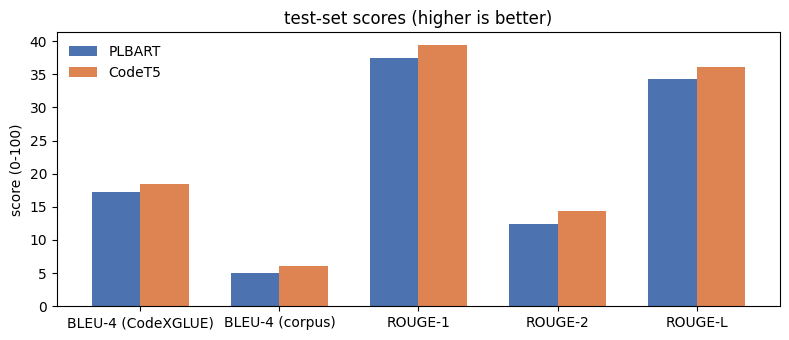

In [19]:
results = pd.DataFrame({
    ("PLBART", "validation"): plbart_val_metrics,
    ("PLBART", "test"): plbart_test_metrics,
    ("CodeT5", "validation"): codet5_val_metrics,
    ("CodeT5", "test"): codet5_test_metrics,
}).T.round(2)
results.index.names = ["model", "split"]
results.to_csv(RESULTS_DIR / "results.csv")
display(results)

ax = results.xs("test", level="split").T.plot.bar(figsize=(8, 3.5), rot=0, width=0.7,
                                                   color=["#4C72B0", "#DD8452"])
ax.set_title("test-set scores (higher is better)")
ax.set_ylabel("score (0-100)")
ax.legend(title=None, frameon=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_scores.png", dpi=150, bbox_inches="tight")


### 6.2 Training curves

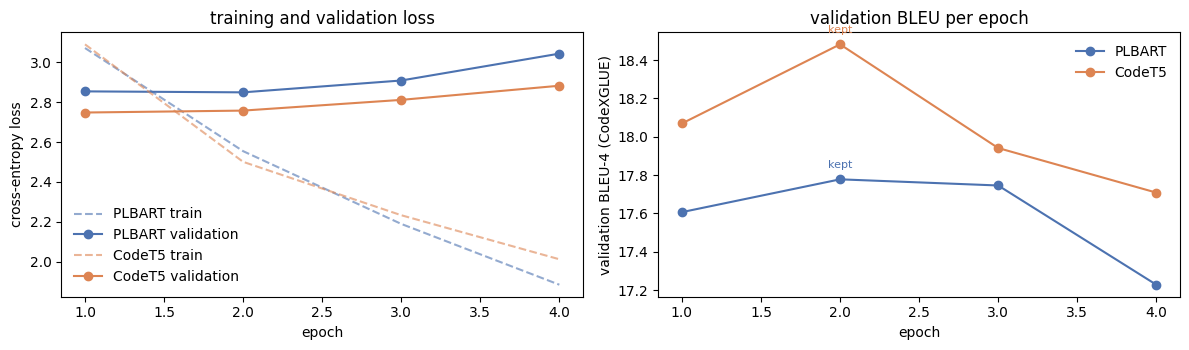

In [20]:
fig, (ax_loss, ax_bleu) = plt.subplots(1, 2, figsize=(12, 3.6))
for name, hist, color in (("PLBART", plbart_history, "#4C72B0"), ("CodeT5", codet5_history, "#DD8452")):
    ax_loss.plot(hist["epoch"], hist["train_loss"], "--", color=color, alpha=0.6, label=f"{name} train")
    ax_loss.plot(hist["epoch"], hist["val_loss"], "-o", color=color, label=f"{name} validation")
    ax_bleu.plot(hist["epoch"], hist["val_bleu"], "-o", color=color, label=name)
    best = hist.loc[hist["val_bleu"].idxmax()]
    ax_bleu.annotate("kept", (best["epoch"], best["val_bleu"]), textcoords="offset points", xytext=(0, 8),
                     ha="center", color=color, fontsize=8)
ax_loss.set(xlabel="epoch", ylabel="cross-entropy loss", title="training and validation loss")
ax_bleu.set(xlabel="epoch", ylabel="validation BLEU-4 (CodeXGLUE)", title="validation BLEU per epoch")
ax_loss.legend(frameon=False)
ax_bleu.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=150, bbox_inches="tight")


### 6.3 Side-by-side predictions

A few test examples where the two models disagree most, which is usually more informative than the
cases both get right.

In [21]:
comparison = pd.DataFrame({
    "reference": text["test"]["target"],
    "PLBART": plbart_test_predictions,
    "CodeT5": codet5_test_predictions,
})
comparison.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

scorer = rouge_scorer.RougeScorer(["rougeL"])
comparison["PLBART rougeL"] = [scorer.score(r, p)["rougeL"].fmeasure for r, p in zip(comparison["reference"], comparison["PLBART"])]
comparison["CodeT5 rougeL"] = [scorer.score(r, p)["rougeL"].fmeasure for r, p in zip(comparison["reference"], comparison["CodeT5"])]
comparison["gap"] = (comparison["PLBART rougeL"] - comparison["CodeT5 rougeL"]).abs()

with pd.option_context("display.max_colwidth", 120):
    display(comparison.sort_values("gap", ascending=False).head(8)[["reference", "PLBART", "CodeT5"]])


,reference,PLBART,CodeT5
729,Convert an AST exclude op to python source code .,Return a list of lines for the exclusion of a function.,Convert an ast . Op to its code .
1320,Factory to make an abstract dist object .,Create a IsSDist instance for a given InstallRequirement.,Make an abstract dist .
281,Get an organisation,Create a new organisation.,Get an organisation .
1035,Starts redirection of stdout,Start the program.,Establish a redirection of stdout .
1337,Create a new author .,Create a NotebookNode with the given name and email and affiliation.,Create a new notebook author .
591,Use SAMtools to create reference index file,Run the samtools on the given ref_id.,Run samtools to create a reference index .
1015,Trivial Per - Triangle parameterization,Per - triangle filter.,Create a parametrization filter for the given script .
36,Print network statistics .,Report the number of parameters.,Report the network statistics .


## 7. Inference on new code

In practice the input is raw source code, so the same preprocessing that produced `code_tokens`
has to be applied: the docstring is removed with the `ast` module and the remaining code is
tokenized with Python's own tokenizer, dropping comments and layout tokens. The helper below wraps
this so the fine-tuned model can be used on any Python function.

In [22]:
def strip_docstrings(source):
    tree = ast.parse(source)
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            body = node.body
            if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                    and isinstance(body[0].value.value, str):
                node.body = body[1:] or [ast.Pass()]
    return ast.unparse(tree)


def code_to_tokens(source):
    skip = {py_tokenize.COMMENT, py_tokenize.NL, py_tokenize.NEWLINE, py_tokenize.INDENT,
            py_tokenize.DEDENT, py_tokenize.ENCODING, py_tokenize.ENDMARKER}
    tokens = py_tokenize.generate_tokens(io.StringIO(strip_docstrings(source)).readline)
    return [tok.string for tok in tokens if tok.type not in skip and tok.string.strip()]


@torch.no_grad()
def summarize(source, model, tokenizer, **generate_kwargs):
    model.to(device).eval()
    encoded = tokenizer(" ".join(code_to_tokens(source)), max_length=MAX_SOURCE_LEN,
                        truncation=True, return_tensors="pt").to(device)
    generated = model.generate(**encoded, max_new_tokens=MAX_TARGET_LEN, num_beams=NUM_BEAMS,
                               early_stopping=True, **generate_kwargs)
    return tokenizer.decode(generated[0], skip_special_tokens=True).strip()


demo_function = '''
def check_file_balance(filename):
    """Checks if a file is balanced.

    A file is balanced if every open parenthesis has a matching closing parenthesis.
    """
    with open(filename, 'r') as f:
        stack = []
        for line in f:
            for char in line:  # scan character by character
                if char == '(':
                    stack.append(char)
                elif char == ')':
                    if not stack:
                        return False
                    stack.pop()
    return not stack
'''

print("model input :", " ".join(code_to_tokens(demo_function))[:200], "...")
print("CodeT5 says :", summarize(demo_function, codet5_model, codet5_tokenizer))


model input : def check_file_balance ( filename ) : with open ( filename , 'r' ) as f : stack = [ ] for line in f : for char in line : if char == '(' : stack . append ( char ) elif char == ')' : if not stack : retu ...
CodeT5 says : Check if the file is balanced .


## 8. Methodology notes

Design decisions that keep the numbers honest. Each of these is easy to get wrong in a code
summarization setup, and several of them inflate scores silently rather than failing loudly.

| concern | decision in this notebook |
|---|---|
| Target visible in the input | Input is `code_tokens` (docstring and comments stripped), verified by the measured leakage check in 2.3. |
| Pre-trained vs. task-fine-tuned checkpoints | Both models start from pre-training only; task-fine-tuned Hub checkpoints for this benchmark are deliberately avoided. |
| Unrepresentative subset | Splits are shuffled with a fixed seed before subsampling instead of taking the first rows of a repository-sorted file. |
| Loss on padding | Labels are padded with `-100`, which the loss ignores. |
| Train/inference mismatch (PLBART) | Targets are tokenized in target mode (`text_target=`) so they end with `__en_XX__`, the same token the decoder is started with. |
| Overfitting | Model selection and early stopping on validation BLEU (the CodeXGLUE criterion); the best checkpoint is restored, not the last epoch. |
| Test-set reuse | Model selection uses only the validation set; the test set is decoded and scored once per model. |
| Metric bookkeeping | Fresh scorer per evaluation; references are the untruncated dataset strings, not decoded label tensors. |
| Metric tokenization | BLEU uses the CodeXGLUE evaluator's normalization, so a prediction that differs from the reference only in spacing around punctuation is not penalized. A plain whitespace split cost PLBART more than 4 BLEU points in an earlier run, because its tokenizer re-attaches punctuation when decoding. |
| Reproducibility | Global seed, seeded shuffling and data-loader order, all hyper-parameters in one configuration cell. |


## 9. Conclusion and next steps

Starting from pre-trained checkpoints and a tenth of the CodeXGLUE Python training data, both models
learn to write concise and mostly accurate one-line summaries within a single Kaggle T4 session.
CodeT5 comes out ahead of PLBART on every metric, by about 1.2 BLEU and 1.9 ROUGE points (Section 6).
For orientation, the CodeXGLUE leaderboard reports BLEU-4 of 19.30 for PLBART and 20.01 for
CodeT5-base on Python after fine-tuning on the full training split, so a tenth of the data already
recovers about 90% of that performance. (The test set here is a 10% sample of the official one, so the comparison is indicative.)

What the run shows:

- **Short, generic summaries.** Both models write shorter summaries than the references, which often
  include a second sentence of detail. Corpus-level BLEU is dominated by its brevity penalty as a
  result, so the per-example CodeXGLUE BLEU is the more informative score.
- **Loss is a weaker selection signal than BLEU.** For CodeT5, validation loss was lowest after
  epoch 1, but validation BLEU peaked after epoch 2 (18.48 against 18.07), so selecting on BLEU kept
  the better checkpoint. For PLBART both criteria picked epoch 2. Both models overfit quickly:
  training loss keeps falling while validation BLEU declines from epoch 3 on.
- **Evaluation details move the ranking.** In an earlier version of this notebook, a naive
  whitespace-split BLEU made PLBART look more than 4 points worse than CodeT5, purely because of
  spacing around punctuation. Using the
  benchmark's own evaluator removes that artifact.

Natural extensions:

- **More data.** Increase `SUBSET_FRACTION`; scores on this benchmark keep improving well past 10%.
- **Other languages.** The dataset has Java, JavaScript, Go, PHP and Ruby configurations; PLBART's
  `src_lang` must be set accordingly.
- **Decoding.** Tune `NUM_BEAMS`, add length penalties or n-gram blocking.
- **Human-oriented evaluation.** BLEU and ROUGE reward lexical overlap; a small manual rating of
  fluency and correctness would complement them.

### References
- Lu et al., *CodeXGLUE: A Machine Learning Benchmark Dataset for Code Understanding and Generation*, 2021.
- Ahmad et al., *Unified Pre-training for Program Understanding and Generation* (PLBART), NAACL 2021.
- Wang et al., *CodeT5: Identifier-aware Unified Pre-trained Encoder-Decoder Models for Code Understanding and Generation*, EMNLP 2021.
- Husain et al., *CodeSearchNet Challenge: Evaluating the State of Semantic Code Search*, 2019.
